In [164]:
!git clone https://github.com/ErenUlger80/GROUP28_CENG313.git
%cd GROUP28_CENG313

fatal: destination path 'GROUP28_CENG313' already exists and is not an empty directory.
/content/GROUP28_CENG313/GROUP28_CENG313


In [165]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [166]:
import pandas as pd
from src.data import load_kaggle_data

train_df, test_df = load_kaggle_data(
    train_path="/content/drive/MyDrive/CENG313_Data/train.csv",
    test_path="/content/drive/MyDrive/CENG313_Data/test.csv"
)

print("Eğitim verisi satır ve sütun sayısı:", train_df.shape)
print("Test verisi satır ve sütun sayısı:", test_df.shape)

display(train_df.head())

Eğitim verisi satır ve sütun sayısı: (57477, 9)
Test verisi satır ve sütun sayısı: (3, 4)


,id,model_a,model_b,prompt,response_a,response_b,winner_model_a,winner_model_b,winner_tie
0,30192,gpt-4-1106-preview,gpt-4-0613,"[""Is it morally right to try to have a certain...","[""The question of whether it is morally right ...","[""As an AI, I don't have personal beliefs or o...",1,0,0
1,53567,koala-13b,gpt-4-0613,"[""What is the difference between marriage lice...","[""A marriage license is a legal document that ...","[""A marriage license and a marriage certificat...",0,1,0
2,65089,gpt-3.5-turbo-0613,mistral-medium,"[""explain function calling. how would you call...","[""Function calling is the process of invoking ...","[""Function calling is the process of invoking ...",0,0,1
3,96401,llama-2-13b-chat,mistral-7b-instruct,"[""How can I create a test set for a very rare ...","[""Creating a test set for a very rare category...","[""When building a classifier for a very rare c...",1,0,0
4,198779,koala-13b,gpt-3.5-turbo-0314,"[""What is the best way to travel from Tel-Aviv...","[""The best way to travel from Tel Aviv to Jeru...","[""The best way to travel from Tel-Aviv to Jeru...",0,1,0


# Veri Kalitesi Kontrolleri
# Bu bölümde eksik değerleri, tekrar kayıtları ve hedef etiketlerinin geçerliliğini inceliycez



In [167]:
import pandas as pd
# Her sütunun veri tipi ve eksik değer sayısını inceliyoruz
# sum() ile bu değerlerin her sütundaki toplam sayısı hesaplanmıştır
quality_summary = pd.DataFrame({
    "Veri tipi": train_df.dtypes.astype(str),
    "Eksik değer sayısı": train_df.isna().sum()
})

display(quality_summary)

print(
    "Tamamen aynı satır sayısı:",
    train_df.duplicated().sum()
)

print(
    "Tekrarlanan id sayısı:",
    train_df["id"].duplicated().sum()
)

text_columns = ["prompt", "response_a", "response_b"]

print(
    "Aynı soru ve cevap çiftinin tekrar sayısı:",
    train_df.duplicated(subset=text_columns).sum()
)

,Veri tipi,Eksik değer sayısı
id,int64,0
model_a,object,0
model_b,object,0
prompt,object,0
response_a,object,0
response_b,object,0
winner_model_a,int64,0
winner_model_b,int64,0
winner_tie,int64,0


Tamamen aynı satır sayısı: 0
Tekrarlanan id sayısı: 0
Aynı soru ve cevap çiftinin tekrar sayısı: 71


In [168]:
target_columns = [
    "winner_model_a",
    "winner_model_b",
    "winner_tie"
]

targets = train_df[target_columns]

binary_values_ok = targets.isin([0, 1]).all(axis=1)

single_winner_ok = targets.sum(axis=1).eq(1)

invalid_rows = ~(binary_values_ok & single_winner_ok)

print(
    "Hatalı hedef etiketi bulunan satır sayısı:",
    invalid_rows.sum()
)

if invalid_rows.any():
    display(
        train_df.loc[
            invalid_rows,
            ["id"] + target_columns
        ].head()
    )
else:
    print("Bütün hedef etiketleri beklenen biçimde.")
    # Hedef etiketlerinin beklenen yapıya uygunluğunu kontrol ediyoruz

Hatalı hedef etiketi bulunan satır sayısı: 0
Bütün hedef etiketleri beklenen biçimde.


In [169]:
import json

# İlk kaydın soru ve cevaplarını JSON metninden Python listesine çeviriyoruz.
prompt_turns = json.loads(train_df.iloc[0]["prompt"])
response_a_turns = json.loads(train_df.iloc[0]["response_a"])
response_b_turns = json.loads(train_df.iloc[0]["response_b"])

print("Dönüşümden önceki veri tipi:")
print(type(train_df.iloc[0]["prompt"]))

print("\nDönüşümden sonraki veri tipi:")
print(type(prompt_turns))

print("\nKullanıcı sorusu sayısı:", len(prompt_turns))
print("A modelinin cevap sayısı:", len(response_a_turns))
print("B modelinin cevap sayısı:", len(response_b_turns))

print("\nKullanıcının soruları:")

for turn_number, question in enumerate(prompt_turns, start=1):
    print(f"{turn_number}. soru: {question}")


Dönüşümden önceki veri tipi:
<class 'str'>

Dönüşümden sonraki veri tipi:
<class 'list'>

Kullanıcı sorusu sayısı: 2
A modelinin cevap sayısı: 2
B modelinin cevap sayısı: 2

Kullanıcının soruları:
1. soru: Is it morally right to try to have a certain percentage of females on managerial positions?
2. soru: OK, does pineapple belong on a pizza? Relax and give me fun answer.


In [170]:
import json
import pandas as pd

# İncelenecek metin sütunları
text_columns = ["prompt", "response_a", "response_b"]

# Her sütunun kontrol sonuçlarını belirten kod blokları
json_results = []

for column in text_columns:
    missing_cells = 0
    invalid_json = 0
    invalid_structure = 0
    empty_lists = 0
    null_turns = 0
    empty_text_turns = 0

    for value in train_df[column]:

        if pd.isna(value):
            missing_cells += 1
            continue

        try:
            turns = json.loads(value)
        except (json.JSONDecodeError, TypeError):
            invalid_json += 1
            continue
        if not isinstance(turns, list):
            invalid_structure += 1
            continue

        if not all(
            turn is None or isinstance(turn, str)
            for turn in turns
        ):
            invalid_structure += 1
            continue

        # Listenin ve içindeki konuşma metinlerinin boşluk kontrolleri
        if len(turns) == 0:
            empty_lists += 1

        for turn in turns:
            if turn is None:
                null_turns += 1
            elif turn.strip() == "":
                empty_text_turns += 1

    json_results.append({
        "Sütun": column,
        "Eksik hücre": missing_cells,
        "Geçersiz JSON": invalid_json,
        "Beklenmeyen yapı": invalid_structure,
        "Boş liste": empty_lists,
        "null tur": null_turns,
        "Boş metin turu": empty_text_turns
    })

json_quality = pd.DataFrame(json_results)

display(json_quality)


,Sütun,Eksik hücre,Geçersiz JSON,Beklenmeyen yapı,Boş liste,null tur,Boş metin turu
0,prompt,0,0,0,0,0,5
1,response_a,0,0,0,0,120,31
2,response_b,0,0,0,0,126,35


In [171]:
import json

# Orijinal veriyi aynı haliyle tutmak için veriyi kopyalıyoruz
prepared_df = train_df.copy()

text_columns = ["prompt", "response_a", "response_b"]

for column in text_columns:

    # JSON metnini Python listesine dönüştürüp yeni sütunda saklıyoruz
    prepared_df[column + "_turns"] = (
        prepared_df[column].apply(json.loads)
    )

    # Listedeki eleman sayısını hesaplama adımı
    prepared_df[column + "_turn_count"] = (
        prepared_df[column + "_turns"].str.len()
    )

# İlk beş kaydın soru ve cevap sayılarını gösteriyoruz
display(
    prepared_df[
        [
            "id",
            "prompt_turn_count",
            "response_a_turn_count",
            "response_b_turn_count"
        ]
    ].head()
)

,id,prompt_turn_count,response_a_turn_count,response_b_turn_count
0,30192,2,2,2
1,53567,3,3,3
2,65089,1,1,1
3,96401,1,1,1
4,198779,1,1,1


In [172]:
# Kazanan bilgisini içeren mevcut sütunlar
target_columns = [
    "winner_model_a",
    "winner_model_b",
    "winner_tie"
]

targets = prepared_df[target_columns]

# Hedef oluşturmadan önce etiketlerin geçerliliğini kontrol ediyoruz
valid_targets = (
    targets.isin([0, 1]).all(axis=1)
    & targets.sum(axis=1).eq(1)
)

if not valid_targets.all():
    raise ValueError(
        "Geçersiz hedef etiketleri var. Önce bu kayıtlar incelenmeli."
    )

# Kazanan sütun adlarını sayısal sınıf etiketlerine eşliyoruz
label_mapping = {
    "winner_model_a": 0,
    "winner_model_b": 1,
    "winner_tie": 2
}

# Her satırda 1 olan sütunu bulup karşılık gelen sınıfı yazıyoruz
prepared_df["target"] = (
    targets.idxmax(axis=1).map(label_mapping)
)

# İlk beş kayıtta dönüşümün sonucunu gösteriyoruz
display(
    prepared_df[target_columns + ["target"]].head()
)

,winner_model_a,winner_model_b,winner_tie,target
0,1,0,0,0
1,0,1,0,1
2,0,0,1,2
3,1,0,0,0
4,0,1,0,1


In [173]:
import json
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Aynı soruyu içeren satırları gruplamak için anahtar oluşturuyoruz
prepared_df["prompt_group"] = prepared_df["prompt_turns"].apply(json.dumps)

# Veriyi %80 eğitim, %20 doğrulama olarak bölüyoruz
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, val_idx = next(splitter.split(prepared_df, groups=prepared_df["prompt_group"]))

train_part = prepared_df.iloc[train_idx].copy()
valid_part = prepared_df.iloc[val_idx].copy()

print("Eğitim veri sayısı:", len(train_part))
print("Doğrulama veri sayısı:", len(valid_part))

# Sınıf oranlarını ekrana yazdırıyoruz
print("\nEğitim Sınıf Dağılımı (%):")
print(train_part["target"].value_counts(normalize=True) * 100)
print("\nDoğrulama Sınıf Dağılımı (%):")
print(valid_part["target"].value_counts(normalize=True) * 100)

Eğitim veri sayısı: 46007
Doğrulama veri sayısı: 11470

Eğitim Sınıf Dağılımı (%):
target
0    34.935988
1    34.253483
2    30.810529
Name: proportion, dtype: float64

Doğrulama Sınıf Dağılımı (%):
target
0    34.795118
1    33.940715
2    31.264167
Name: proportion, dtype: float64


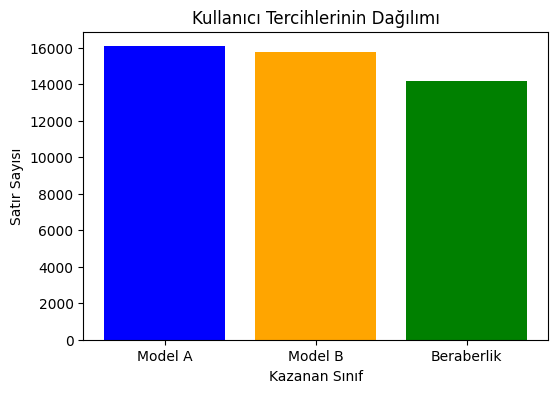

In [174]:
import pandas as pd
import matplotlib.pyplot as plt

# Sınıfları grafik üzerinden gösteriyoruz
sinif_sayilari = train_part["target"].value_counts()
sinif_isimleri = ["Model A", "Model B", "Beraberlik"]

plt.figure(figsize=(6, 4))
plt.bar(sinif_isimleri, sinif_sayilari, color=["blue", "orange", "green"])
plt.title("Kullanıcı Tercihlerinin Dağılımı")
plt.xlabel("Kazanan Sınıf")
plt.ylabel("Satır Sayısı")
plt.show()

In [175]:
import pandas as pd

# Soruların ve cevapların kelime sayılarını hesaplayıyoruz
for col in ["prompt", "response_a", "response_b"]:
    word_counts = []
    for turns in train_part[col + "_turns"]:
        # Her satırdaki konuşmaların toplam kelime sayısını buluyoruz
        total_words = sum(len(str(turn).split()) for turn in turns if turn is not None)
        word_counts.append(total_words)

    train_part[col + "_word_count"] = word_counts

# Temel istatistikleri ekrana yazdırıyoruz
display(train_part[["prompt_word_count", "response_a_word_count", "response_b_word_count"]].describe())

,prompt_word_count,response_a_word_count,response_b_word_count
count,46007.000000,46007.000000,46007.000000
mean,55.863999,212.541526,212.907318
std,148.438898,226.281938,226.921254
min,1.000000,0.000000,0.000000
25%,9.000000,66.000000,67.000000
50%,16.000000,169.000000,171.000000
75%,41.000000,290.000000,291.000000
max,4809.000000,9184.000000,6893.000000


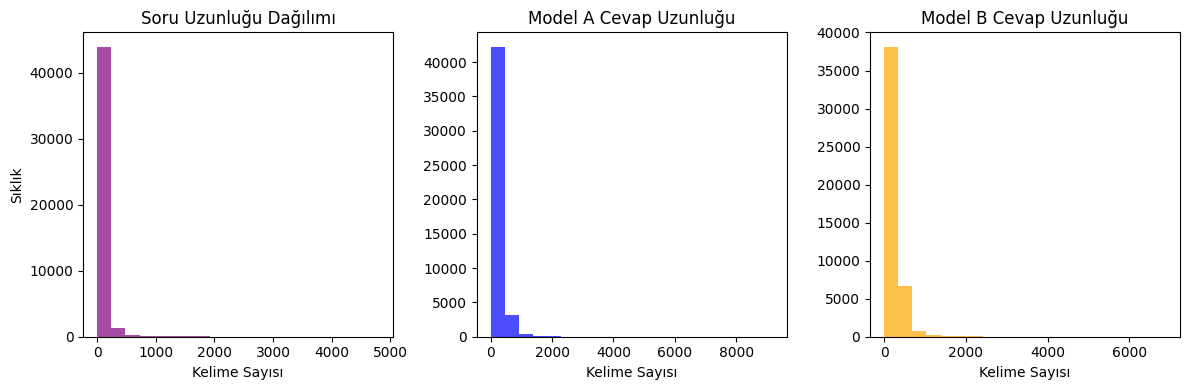

In [176]:
import matplotlib.pyplot as plt

# Soruların ve cevapların kelime uzunluklarını gösteriyoruz
plt.figure(figsize=(12, 4))

# 1. Soru Uzunlukları
plt.subplot(1, 3, 1)
plt.hist(train_part["prompt_word_count"].dropna(), bins=20, color="purple", alpha=0.7)
plt.title("Soru Uzunluğu Dağılımı")
plt.xlabel("Kelime Sayısı")
plt.ylabel("Sıklık")

# 2. Model A Cevap Uzunlukları
plt.subplot(1, 3, 2)
plt.hist(train_part["response_a_word_count"].dropna(), bins=20, color="blue", alpha=0.7)
plt.title("Model A Cevap Uzunluğu")
plt.xlabel("Kelime Sayısı")

# 3. Model B Cevap Uzunlukları
plt.subplot(1, 3, 3)
plt.hist(train_part["response_b_word_count"].dropna(), bins=20, color="orange", alpha=0.7)
plt.title("Model B Cevap Uzunluğu")
plt.xlabel("Kelime Sayısı")

plt.tight_layout()
plt.show()

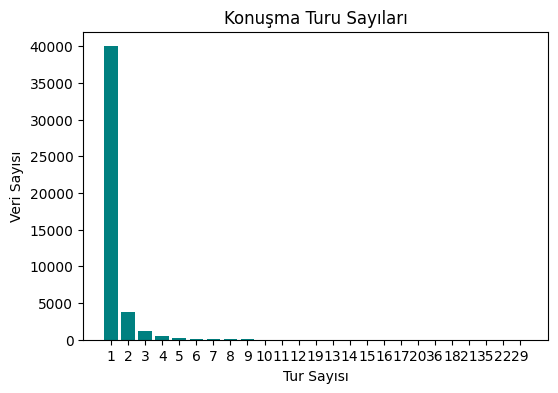

In [177]:
import matplotlib.pyplot as plt

# Konuşmalardaki tur sayılarının dağılımını gösteren grafik
tur_sayilari = train_part["prompt_turn_count"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(tur_sayilari.index.astype(str), tur_sayilari.values, color="teal")
plt.title("Konuşma Turu Sayıları")
plt.xlabel("Tur Sayısı")
plt.ylabel("Veri Sayısı")
plt.show()

In [181]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier

# Eğitim ve doğrulama kümelerindeki gerçek hedef etiketlerini alıyoruz
y_train = train_part["target"].to_numpy()
y_valid = valid_part["target"].to_numpy()

# DummyClassifier için özellik matrisine gerek olmadığından sadece sıfırlardan oluşan basit girdiler tanımlıyoruz
X_dummy_train = np.zeros((len(train_part), 1))
X_dummy_valid = np.zeros((len(valid_part), 1))

# Sınıf oranlarına göre tahmin üreten baseline modelimizi tanımlayıp eğitiyoruz
dummy_model = DummyClassifier(strategy="prior")
dummy_model.fit(X_dummy_train, y_train)

# Modelin eğitim verisinden çıkardığı sınıf olasılıklarını bir tablo halinde inceliyoruz
prior_table = pd.DataFrame({
    "Sınıf": ["A Modeli Kazandı", "B Modeli Kazandı", "Beraberlik"],
    "Eğitim Oranı (%)": (dummy_model.class_prior_ * 100).round(2)
})

display(prior_table)

,Sınıf,Eğitim Oranı (%)
0,A Modeli Kazandı,34.94
1,B Modeli Kazandı,34.25
2,Beraberlik,30.81


In [180]:
from sklearn.metrics import accuracy_score, log_loss

# Tanımladığımız X_dummy_valid matrisini kullanarak tahminleri alıyoruz
prob_predictions = dummy_model.predict_proba(X_dummy_valid)
class_predictions = dummy_model.predict(X_dummy_valid)

# Başarı metriklerini hesaplıyoruz
loss_value = log_loss(y_valid, prob_predictions)
acc_value = accuracy_score(y_valid, class_predictions)

print(f"Baseline Doğrulama Log Loss Skoru: {loss_value:.4f}")
print(f"Baseline Doğrulama Accuracy (%) Skoru: {acc_value * 100:.2f}%")

Baseline Doğrulama Log Loss Skoru: 1.0976
Baseline Doğrulama Accuracy (%) Skoru: 34.80%
